# Association Rules: Which Policy Attributes Go Together with High-Severity Claims?

**DSC 411/511 Semester Project** · Venkat Repaka, Ritik Gaire

**Question.** Which policy attributes co-occur with **high-severity** claims (top 20% of building damage, the RQ2 target)?
Does the answer change between **legacy-rated** policies and **Risk Rating 2.0** policies?

**Method.** Apriori and FP-Growth (`mlxtend`). Each claim is one "basket" of items such as `zone=AE`, `deductible=$5,000`,
`foundation=slab`. We keep the rules whose right-hand side (consequent) is `severity=high` and report **support**,
**confidence** and **lift**.

| Measure | Meaning here |
|---|---|
| support | share of claims that have all the items of the rule |
| confidence | of the claims with the left-hand side, the share that are high severity |
| lift | confidence ÷ the overall share of high-severity claims. 1 = no link; 1.5 = 50% more likely than average; below 1 = less likely |

**What the claims file cannot answer.** The original plan also asked for *premium change*, *lapse* and `mandatoryPurchaseFlag`.
None of these is in the NFIP **claims** file. They are in FEMA's separate NFIP **policies** file, and the two redacted files
share no policy ID, so a claim cannot be matched to its policy history. Lapse rules are therefore left out of this notebook.

---
# Section 1: Data and items

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
import warnings; warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 90); pd.set_option('display.width', 200)

w = pd.read_parquet('outputs/nfip_claims_simple_clean.parquet',
                    columns=['dateOfLoss', 'high_severity', 'rateMethod', 'flood_zone_family', 'bldg_deductible_usd',
                             'foundationType', 'occupancyType'])
print(f'All claims: {len(w):,}')
w = w[w['high_severity'].notna()].copy()
print(f'Claims with a known severity (building damage recorded): {len(w):,}')
print(f"High-severity share: {w['high_severity'].mean():.1%}")

All claims: 276,570
Claims with a known severity (building damage recorded): 243,861
High-severity share: 20.0%


## 1.1 Turn each attribute into items (discretization)

| Attribute | Items | Note |
|---|---|---|
| flood zone | `zone=AE`, `zone=X`, `zone=V`, ... | zone family from notebook 03 |
| building deductible | `deductible<=$1,000`, `=$1,250`, `=$2,000`, `=$5,000`, `>=$10,000` | ordered bins |
| foundation | `foundation=slab`, `=basement`, `=crawlspace`, `=elevated (4/5/6)`, `=not recorded` | code 0 is used only by legacy policies and means "not recorded" |
| occupancy | `occupancy=single family`, `=2-4 units`, ... | legacy codes translated: 1→11, 2→12, 3→13, 4 and 6→18 |
| rate method | `rating=RR2.0` or `rating=legacy` | Risk Rating 2.0 is rate method `RE` |
| severity | `severity=high` or `severity=not high` | top 20% of building damage (cut-off $106,127) |

Foundation codes 4, 5 and 6 are all elevated types (on piles, piers or walls), so we keep them apart but label them as elevated.

In [2]:
def ded_bin(v):
    if pd.isna(v): return 'deductible=unknown'
    if v <= 1000: return 'deductible<=$1,000'
    if v <= 1250: return 'deductible=$1,250'
    if v <= 2000: return 'deductible=$2,000'
    if v <= 5000: return 'deductible=$5,000'
    return 'deductible>=$10,000'
FOUND = {'0': 'not recorded', '1': 'slab', '2': 'basement', '3': 'crawlspace',
         '4': 'elevated (4)', '5': 'elevated (5)', '6': 'elevated (6)'}
OCC = {11: 'single family', 12: '2-4 units', 13: '5+ units', 14: 'mobile home', 15: 'condo building',
       16: 'unit in building', 17: 'non-res. mobile', 18: 'non-residential', 19: 'non-res. unit'}
occ = w['occupancyType'].replace({1: 11, 2: 12, 3: 13, 4: 18, 6: 18})

items = pd.DataFrame({
    'zone': 'zone=' + w['flood_zone_family'].astype(str),
    'deductible': w['bldg_deductible_usd'].map(ded_bin),
    'foundation': 'foundation=' + w['foundationType'].astype(str).map(FOUND).fillna('other'),
    'occupancy': 'occupancy=' + occ.map(OCC).fillna('other'),
    'rating': np.where(w['rateMethod'] == 'RE', 'rating=RR2.0', 'rating=legacy'),
    'severity': np.where(w['high_severity'] == 1, 'severity=high', 'severity=not high')}, index=w.index)
for c in items.columns:
    print(c, items[c].value_counts(normalize=True).round(3).head(8).to_dict())

zone {'zone=AE': 0.723, 'zone=X': 0.178, 'zone=V': 0.038, 'zone=A': 0.037, 'zone=AH': 0.015, 'zone=AO': 0.006, 'zone=A99': 0.004, 'zone=other': 0.0}
deductible {'deductible=$2,000': 0.33, 'deductible=$1,250': 0.307, 'deductible=$5,000': 0.212, 'deductible>=$10,000': 0.095, 'deductible<=$1,000': 0.057}
foundation {'foundation=slab': 0.547, 'foundation=not recorded': 0.093, 'foundation=basement': 0.091, 'foundation=crawlspace': 0.076, 'foundation=elevated (5)': 0.073, 'foundation=elevated (6)': 0.06, 'foundation=elevated (4)': 0.06}
occupancy {'occupancy=single family': 0.773, 'occupancy=non-residential': 0.068, 'occupancy=condo building': 0.061, 'occupancy=2-4 units': 0.042, 'occupancy=mobile home': 0.023, 'occupancy=5+ units': 0.018, 'occupancy=unit in building': 0.015, 'occupancy=non-res. mobile': 0.0}
rating {'rating=RR2.0': 0.899, 'rating=legacy': 0.101}
severity {'severity=not high': 0.8, 'severity=high': 0.2}


In [3]:
B = pd.get_dummies(items, prefix='', prefix_sep='').astype(bool)    # one True/False column per item
print('Baskets:', B.shape[0], '  items:', B.shape[1])
BASE = B['severity=high'].mean()
print(f'Overall share of high-severity claims (the lift baseline): {BASE:.3f}')

Baskets: 243861   items: 33
Overall share of high-severity claims (the lift baseline): 0.200


---
# Section 2: Frequent itemsets with Apriori and FP-Growth

**Minimum support = 1%** (an itemset must appear in at least about 2,400 claims). Smaller groups give unstable rules.
Both algorithms must find the same itemsets; FP-Growth is usually faster because it does not generate candidates.

In [4]:
MIN_SUPPORT = 0.01
t0 = time.time(); fi_ap = apriori(B, min_support=MIN_SUPPORT, use_colnames=True); t_ap = time.time() - t0
t0 = time.time(); fi_fp = fpgrowth(B, min_support=MIN_SUPPORT, use_colnames=True); t_fp = time.time() - t0
same = set(map(frozenset, fi_ap['itemsets'])) == set(map(frozenset, fi_fp['itemsets']))
print(f'Apriori : {len(fi_ap):>5} itemsets in {t_ap:.1f} s')
print(f'FP-Growth: {len(fi_fp):>5} itemsets in {t_fp:.1f} s')
print('Same itemsets:', same)

Apriori :   889 itemsets in 0.5 s
FP-Growth:   889 itemsets in 0.7 s
Same itemsets: True


---
# Section 3: Rules with `severity=high` on the right-hand side (all claims)

We keep rules whose consequent is exactly `{severity=high}` and whose left-hand side has 1 to 3 items.

In [5]:
def severity_rules(fi, min_support=MIN_SUPPORT):
    r = association_rules(fi, metric='lift', min_threshold=0.0)
    r = r[r['consequents'] == frozenset({'severity=high'})].copy()
    r = r[~r['antecedents'].map(lambda a: any(x.startswith('severity=') for x in a))]
    r['rule'] = r['antecedents'].map(lambda a: ' + '.join(sorted(a)))
    r['items'] = r['antecedents'].map(len)
    return r[['rule', 'items', 'support', 'confidence', 'lift']].sort_values('lift', ascending=False).reset_index(drop=True)

rules_all = severity_rules(fi_fp)
print('Rules with severity=high as consequent:', len(rules_all))
print('\nStrongest positive rules (highest lift):')
rules_all.head(15).round(3)

Rules with severity=high as consequent: 99

Strongest positive rules (highest lift):


,rule,items,support,confidence,lift
0,foundation=slab + occupancy=condo building + rating=RR2.0 + zone=AE,4,0.015,0.607,3.033
1,foundation=slab + occupancy=condo building + zone=AE,3,0.015,0.590,2.950
2,foundation=slab + occupancy=condo building + rating=RR2.0,3,0.017,0.585,2.925
3,"deductible>=$10,000 + foundation=slab + rating=RR2.0 + zone=AE",4,0.028,0.509,2.547
4,"deductible>=$10,000 + foundation=slab + zone=AE",3,0.028,0.509,2.547
5,"deductible>=$10,000 + foundation=slab",2,0.030,0.505,2.524
6,"deductible>=$10,000 + foundation=slab + rating=RR2.0",3,0.030,0.505,2.524
7,"deductible>=$10,000 + foundation=slab + occupancy=single family + zone=AE",4,0.017,0.482,2.412
8,"deductible>=$10,000 + foundation=slab + occupancy=single family + rating=RR2.0 + zone=AE",5,0.017,0.482,2.412
9,"deductible>=$10,000 + foundation=slab + occupancy=single family + rating=RR2.0",4,0.018,0.478,2.391


In [6]:
print('Rules with the lowest lift (claims with these items are rarely high severity):')
rules_all.tail(10).iloc[::-1].round(3)

Rules with the lowest lift (claims with these items are rarely high severity):


,rule,items,support,confidence,lift
98,zone=X,1,0.013,0.074,0.372
97,rating=RR2.0 + zone=X,2,0.012,0.081,0.404
96,"deductible=$1,250 + occupancy=single family",2,0.023,0.095,0.477
95,"deductible=$1,250 + occupancy=single family + rating=RR2.0",3,0.021,0.102,0.512
94,"deductible=$1,250 + occupancy=single family + zone=AE",3,0.017,0.119,0.594
93,"deductible=$1,250 + occupancy=single family + rating=RR2.0 + zone=AE",4,0.016,0.121,0.605
92,"deductible=$1,250",1,0.038,0.125,0.624
91,"deductible=$1,250 + rating=RR2.0",2,0.036,0.134,0.668
90,foundation=crawlspace + rating=RR2.0,2,0.011,0.140,0.700
89,foundation=crawlspace,1,0.011,0.140,0.700


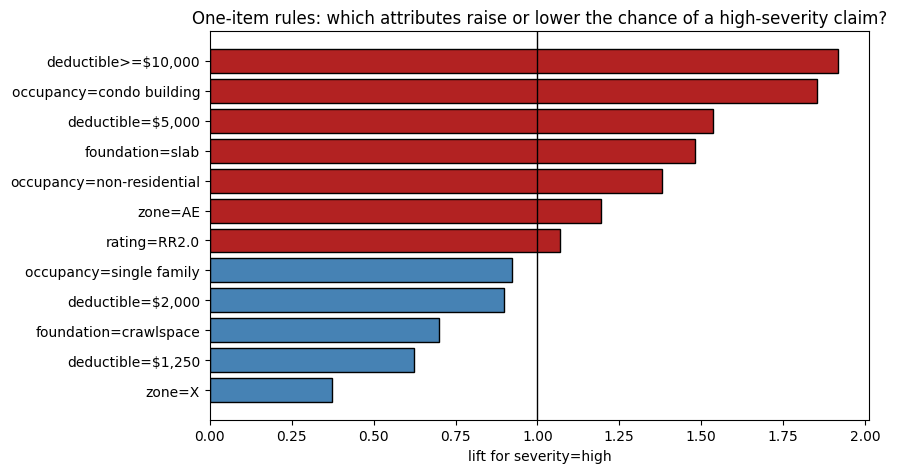

In [7]:
single = rules_all[rules_all['items'] == 1].sort_values('lift')
fig, ax = plt.subplots(figsize=(9, 0.32 * len(single) + 1))
ax.barh(single['rule'], single['lift'], color=np.where(single['lift'] >= 1, 'firebrick', 'steelblue'), edgecolor='black')
ax.axvline(1, color='black', lw=1); ax.set_xlabel('lift for severity=high'); ax.set_title('One-item rules: which attributes raise or lower the chance of a high-severity claim?')
plt.tight_layout(); plt.show()

## 3.1 Every single attribute, without a minimum support

The 1% minimum support hides rules for items that are rare among high-severity claims (for example elevated foundations).
Here we compute confidence and lift for **every** item directly, so the protective items are visible too.

In [8]:
single_all = []
for item in B.columns:
    if item.startswith('severity=') or B[item].sum() < 100: continue
    conf = B.loc[B[item], 'severity=high'].mean()
    single_all.append({'item': item, 'claims with item': int(B[item].sum()), 'support of rule': (B[item] & B['severity=high']).mean(),
                       'confidence': conf, 'lift': conf / BASE})
single_all = pd.DataFrame(single_all).sort_values('lift', ascending=False).reset_index(drop=True)
single_all.round(3)

,item,claims with item,support of rule,confidence,lift
0,occupancy=5+ units,4374,0.007,0.393,1.966
1,"deductible>=$10,000",23147,0.036,0.384,1.918
2,occupancy=condo building,14784,0.022,0.371,1.853
3,"deductible=$5,000",51676,0.065,0.307,1.536
4,foundation=slab,133370,0.162,0.296,1.480
5,occupancy=non-residential,16616,0.019,0.276,1.381
6,zone=AE,176337,0.173,0.239,1.195
7,zone=V,9302,0.009,0.230,1.149
8,rating=RR2.0,219311,0.192,0.214,1.068
9,occupancy=2-4 units,10142,0.008,0.192,0.962


---
# Section 4: Legacy rating vs Risk Rating 2.0

We mine the rules **separately** for claims on legacy-rated policies and on RR2.0 policies, and compare the same rule in both.

Three things to keep in mind:
- **`rateMethod` is the policy's latest rating, not the rating on the day of the flood.** RR2.0 started in October 2021,
  but most 2020 claims are marked RR2.0 (table below). "Legacy" therefore means *a policy whose record never moved to RR2.0*.
  For a true before/after comparison we also split by **date of loss** in Section 4.2.
- **Legacy policies did not record the foundation** (93% are code 0), so foundation rules exist almost only for RR2.0.
- **The two groups come from different years.** Legacy-rated claims are mostly 2020-2021; RR2.0 claims are mostly 2022-2024,
  the years of Ian, Helene and Milton. A rule can change because the **storms** changed, not only the rating.

In [9]:
print('Claims by loss year and rating (%, each column sums to 100):')
print((pd.crosstab(w['dateOfLoss'].dt.year, items['rating'], normalize='columns') * 100).round(1).to_string())
print()
groups = {}
for label in ['rating=legacy', 'rating=RR2.0']:
    sub = B[B[label]].drop(columns=['rating=legacy', 'rating=RR2.0'])
    sub = sub.loc[:, sub.any()]
    fi = fpgrowth(sub, min_support=MIN_SUPPORT, use_colnames=True)
    groups[label] = (severity_rules(fi), sub['severity=high'].mean(), len(sub))
    print(f"{label:14s} claims {len(sub):>7,}   high-severity share {sub['severity=high'].mean():.3f}   rules {len(groups[label][0])}")

Claims by loss year and rating (%, each column sums to 100):


rating      rating=RR2.0  rating=legacy
dateOfLoss                             
2020                 8.3           43.1
2021                14.6           41.3
2022                22.1            8.3
2023                 8.6            0.5
2024                41.1            6.0
2025                 5.3            1.0

rating=legacy  claims  24,550   high-severity share 0.079   rules 37


rating=RR2.0   claims 219,311   high-severity share 0.214   rules 51


In [10]:
L, R = groups['rating=legacy'][0].set_index('rule'), groups['rating=RR2.0'][0].set_index('rule')
cmp = L[['support', 'confidence', 'lift']].join(R[['support', 'confidence', 'lift']], how='outer', lsuffix=' legacy', rsuffix=' RR2.0')
cmp['lift change'] = cmp['lift RR2.0'] - cmp['lift legacy']
both = cmp.dropna().sort_values('lift change')
print(f'Rules found in both groups: {len(both)}   only legacy: {cmp["lift RR2.0"].isna().sum()}   only RR2.0: {cmp["lift legacy"].isna().sum()}')
both.round(3)

Rules found in both groups: 17   only legacy: 20   only RR2.0: 34


,support legacy,confidence legacy,lift legacy,support RR2.0,confidence RR2.0,lift RR2.0,lift change
rule,,,,,,,
occupancy=non-residential,0.015,0.202,2.556,0.019,0.285,1.334,-1.221
"deductible=$1,250 + zone=AE",0.011,0.098,1.241,0.028,0.150,0.702,-0.539
"deductible>=$10,000",0.011,0.188,2.382,0.039,0.397,1.858,-0.523
"deductible=$2,000",0.019,0.089,1.130,0.064,0.186,0.871,-0.259
"deductible=$5,000 + zone=AE",0.016,0.141,1.782,0.066,0.332,1.554,-0.228
zone=X,0.016,0.048,0.603,0.013,0.081,0.379,-0.224
zone=AE,0.055,0.110,1.385,0.186,0.249,1.165,-0.219
"deductible=$1,250",0.026,0.067,0.843,0.040,0.134,0.626,-0.218
"deductible=$1,250 + occupancy=single family",0.019,0.053,0.675,0.024,0.102,0.480,-0.196


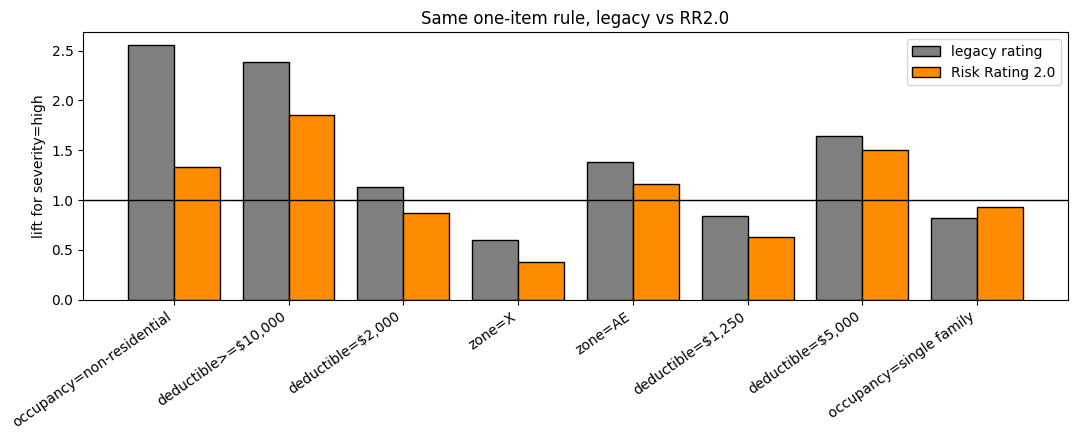

In [11]:
one = both[[r.count('+') == 0 for r in both.index]]
x = np.arange(len(one))
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(x - 0.2, one['lift legacy'], 0.4, label='legacy rating', color='grey', edgecolor='black')
ax.bar(x + 0.2, one['lift RR2.0'], 0.4, label='Risk Rating 2.0', color='darkorange', edgecolor='black')
ax.axhline(1, color='black', lw=1); ax.set_xticks(x, one.index, rotation=35, ha='right'); ax.set_ylabel('lift for severity=high')
ax.set_title('Same one-item rule, legacy vs RR2.0'); ax.legend(); plt.tight_layout(); plt.show()

In [12]:
print('Strongest rules that exist only for RR2.0 claims (mostly foundation rules):')
R.loc[cmp.index[cmp['lift legacy'].isna()].intersection(R.index)].sort_values('lift', ascending=False).head(10).round(3)

Strongest rules that exist only for RR2.0 claims (mostly foundation rules):


,items,support,confidence,lift
rule,,,,
foundation=slab + occupancy=condo building + zone=AE,3,0.017,0.607,2.841
foundation=slab + occupancy=condo building,2,0.019,0.585,2.740
"deductible>=$10,000 + foundation=slab + zone=AE",3,0.031,0.509,2.386
"deductible>=$10,000 + foundation=slab",2,0.033,0.505,2.364
"deductible>=$10,000 + foundation=slab + occupancy=single family + zone=AE",4,0.018,0.482,2.259
"deductible>=$10,000 + foundation=slab + occupancy=single family",3,0.020,0.478,2.240
occupancy=condo building + zone=AE,2,0.021,0.425,1.990
"deductible=$5,000 + foundation=slab + zone=AE",3,0.059,0.422,1.978
"deductible=$5,000 + foundation=slab + occupancy=single family + zone=AE",4,0.049,0.419,1.965


## 4.1 Same years, different rating

To separate the rating from the storms, we compare the two ratings **inside the same loss year** (2020 and 2021, the years
with enough claims of both kinds), using the one-item rules found in both.

In [13]:
rows = []
for yr in [2020, 2021]:
    for label in ['rating=legacy', 'rating=RR2.0']:
        m = (w['dateOfLoss'].dt.year == yr).values & B[label].values
        sub = B[m]; base = sub['severity=high'].mean()
        for item in one.index:
            has = sub[item]
            if has.mean() < 0.01 or has.sum() < 100: continue
            conf = sub.loc[has, 'severity=high'].mean()
            rows.append({'year': yr, 'rating': label.split('=')[1], 'item': item, 'claims with item': int(has.sum()),
                         'confidence': conf, 'lift': conf / base})
yr_cmp = pd.DataFrame(rows).pivot_table(index='item', columns=['year', 'rating'], values='lift')
yr_cmp.round(2)

year                       2020         2021       
rating                    RR2.0 legacy RR2.0 legacy
item                                               
deductible=$1,250          1.25   0.99  1.14   0.87
deductible=$2,000          0.67   1.06  0.73   0.94
deductible=$5,000          1.08   1.47  1.30   1.48
deductible>=$10,000        1.85   2.12  1.93   2.07
occupancy=non-residential  3.49   3.27  2.97   2.54
occupancy=single family    0.60   0.73  0.74   0.80
zone=AE                    1.03   1.19  1.28   1.38
zone=X                     0.88   0.80  0.58   0.57

## 4.2 Before vs after Risk Rating 2.0, by date of loss

- **Before:** losses before **1 October 2021** (RR2.0 started for new policies on that day).
- **After:** losses on or after **1 April 2022** (by then every renewing policy had moved to RR2.0).
- Losses in between are left out, because policies were still switching.

The rating item is left out here, since the period already says which system was in force.

In [14]:
loss = w['dateOfLoss']
periods = {'before RR2.0 (loss < Oct 2021)': (loss < '2021-10-01').values,
           'after RR2.0 (loss >= Apr 2022)': (loss >= '2022-04-01').values}
per = {}
for label, m in periods.items():
    sub = B[m].drop(columns=['rating=legacy', 'rating=RR2.0'])
    sub = sub.loc[:, sub.any()]
    fi = fpgrowth(sub, min_support=MIN_SUPPORT, use_colnames=True)
    per[label] = severity_rules(fi).set_index('rule')
    print(f"{label:32s} claims {len(sub):>7,}   high-severity share {sub['severity=high'].mean():.3f}   rules {len(per[label])}")
print('Foundation recorded (not code 0):', {k: f"{(~B.loc[m, 'foundation=not recorded']).mean():.0%}" for k, m in periods.items()})
a, b = per['before RR2.0 (loss < Oct 2021)'], per['after RR2.0 (loss >= Apr 2022)']
pcmp = a[['confidence', 'lift']].join(b[['confidence', 'lift']], how='inner', lsuffix=' before', rsuffix=' after')
pcmp['lift change'] = pcmp['lift after'] - pcmp['lift before']
pcmp.sort_values('lift after', ascending=False).round(3)

before RR2.0 (loss < Oct 2021)   claims  68,661   high-severity share 0.074   rules 26


after RR2.0 (loss >= Apr 2022)   claims 171,780   high-severity share 0.253   rules 54
Foundation recorded (not code 0): {'before RR2.0 (loss < Oct 2021)': '71%', 'after RR2.0 (loss >= Apr 2022)': '99%'}


,confidence before,lift before,confidence after,lift after,lift change
rule,,,,,
foundation=slab + zone=AE,0.153,2.076,0.379,1.494,-0.582
foundation=slab + occupancy=single family + zone=AE,0.126,1.708,0.369,1.457,-0.251
"deductible=$5,000 + zone=AE",0.107,1.460,0.363,1.431,-0.028
"deductible=$5,000",0.100,1.354,0.354,1.395,0.041
foundation=slab,0.111,1.511,0.337,1.330,-0.181
foundation=slab + occupancy=single family,0.083,1.134,0.329,1.298,0.164
occupancy=non-residential + zone=AE,0.240,3.256,0.324,1.277,-1.979
occupancy=non-residential,0.220,2.982,0.305,1.205,-1.777
zone=AE,0.092,1.251,0.284,1.122,-0.130


In [15]:
print('Strongest rules after RR2.0 that were not found before (support below 1% or items not recorded):')
b.loc[b.index.difference(a.index)].sort_values('lift', ascending=False).head(10).round(3)

Strongest rules after RR2.0 that were not found before (support below 1% or items not recorded):


,items,support,confidence,lift
rule,,,,
foundation=slab + occupancy=condo building + zone=AE,3,0.021,0.599,2.364
"deductible>=$10,000 + foundation=slab + zone=AE",3,0.038,0.526,2.075
"deductible>=$10,000 + foundation=slab",2,0.041,0.523,2.063
"deductible>=$10,000 + foundation=slab + occupancy=single family + zone=AE",4,0.023,0.499,1.969
"deductible>=$10,000 + foundation=slab + occupancy=single family",3,0.025,0.497,1.961
foundation=slab + occupancy=condo building,2,0.024,0.479,1.889
occupancy=condo building + zone=AE,2,0.027,0.448,1.766
"deductible>=$10,000 + zone=AE",2,0.044,0.441,1.741
"deductible=$5,000 + foundation=slab + zone=AE",3,0.073,0.441,1.741


---
# Section 5: What the rules say

## Which attributes co-occur with high-severity claims? (all 243,861 claims, baseline 20%)

| Rule (left-hand side → severity=high) | Confidence | Lift |
|---|---|---|
| slab + condo building + zone AE | 59% | **2.95** |
| deductible ≥ $10,000 + slab | 51% | **2.52** |
| slab + condo building | 47% | 2.37 |
| deductible $5,000 + slab + zone AE | 42% | 2.11 |
| one item: 5+ units / deductible ≥ $10,000 / condo building | 37-39% | 1.85-1.97 |
| one item: slab | 30% | 1.48 |

Items that **lower** the chance (lift below 1, Section 3.1): elevated foundations (lift 0.26-0.50), basement (0.29),
zone X (0.37), zone A99 / AO / AH (0.20-0.52), mobile homes (0.16), units inside a building (0.10) and deductibles of $1,000 or less (0.08).

**Reading these rules carefully**
- **"High severity" is a dollar cut-off ($106,127 of building damage).** Large buildings cross it more easily. Condo buildings,
  5+ unit buildings and high deductibles (which owners of expensive buildings choose) all mark **big buildings**, so part of their
  lift is building size, not flood risk.
- **Slab foundation is the clearest risk item** that is not about size: it appears in almost every strong rule, while every
  elevated foundation type has a lift around 0.3-0.5. This is the same message as RQ3 (notebook 05_rq3_check).
- **Mobile homes and small deductibles look "safe" only because their coverage is low** (median coverage about $71,000 for
  mobile homes, below the $106,127 cut-off). They are not safer buildings.
- Rules are **co-occurrence, not cause**. Zone AE has lift 1.2 partly because the big hurricanes hit AE-zone coasts.

## Legacy vs Risk Rating 2.0

**By rating method (Section 4).** Legacy-rated claims are much less often high severity (7.9% vs 21.4%). But `rateMethod`
holds the policy's **latest** rating: most 2020 claims are marked RR2.0, which started only in October 2021. So "legacy" means
"a policy whose record never moved to RR2.0". This comparison cannot show the effect of the rating change.

**By date of loss (Section 4.2), the fairer comparison.**
- High-severity share: **7.4% before** (losses before Oct 2021) vs **25.3% after** (losses from Apr 2022). The difference comes from
  the storms (Ian, Helene, Milton) more than from the rating system.
- **Most attributes point the same way before and after**: slab, zone AE, $5,000 deductibles and non-residential buildings have
  lift above 1 in both periods; zone X stays below 1 (0.65 → 0.41). One exception: $1,250 deductibles move from about average
  (1.06) to clearly below average (0.62).
- **Lifts are smaller after**, because the baseline rose from 7% to 25%: when a quarter of all claims are severe, no group can be
  many times above average. Example: non-residential buildings went from lift 2.98 to 1.21, although their confidence rose (22% → 31%).
- **New strong rules appear only after**, mostly with slab + condo or slab + high deductible (lift 1.7-2.4). These are not
  new risks: before 2021 the combinations were below the 1% support or the foundation was not recorded.

## Answer
> Yes, clear patterns exist. High-severity claims go together with **slab foundations**, **zone AE**, **condo and multi-unit
> buildings** and **high deductibles** (lift up to about 3); **elevated foundations, zone X and low-coverage buildings**
> go together with low severity (lift 0.1-0.5). The direction of most rules is the **same before and after Risk Rating 2.0**.
> The rules are weaker after 2022 only because severe claims became much more common (Ian, Helene, Milton).
> Rules about **lapse** and **premium change** cannot be mined from the claims file; they need FEMA's NFIP policies file.